<a href="https://colab.research.google.com/github/dilekmirac/dip/blob/main/hafta6_g%C3%B6rev5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import torch

print(f"OpenCV Versiyonu: {cv2.__version__}")
print(f"CUDA Kullanılabilir mi (PyTorch/GPU): {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"Aktif GPU Modeli: {torch.cuda.get_device_name(0)}")

OpenCV Versiyonu: 4.14.0
CUDA Kullanılabilir mi (PyTorch/GPU): True
Aktif GPU Modeli: Tesla T4


Maksimum eş merkezli oylama puanı: 279 | Eşik değer: 181
Çizilen eş merkezli çember sayısı: 3486


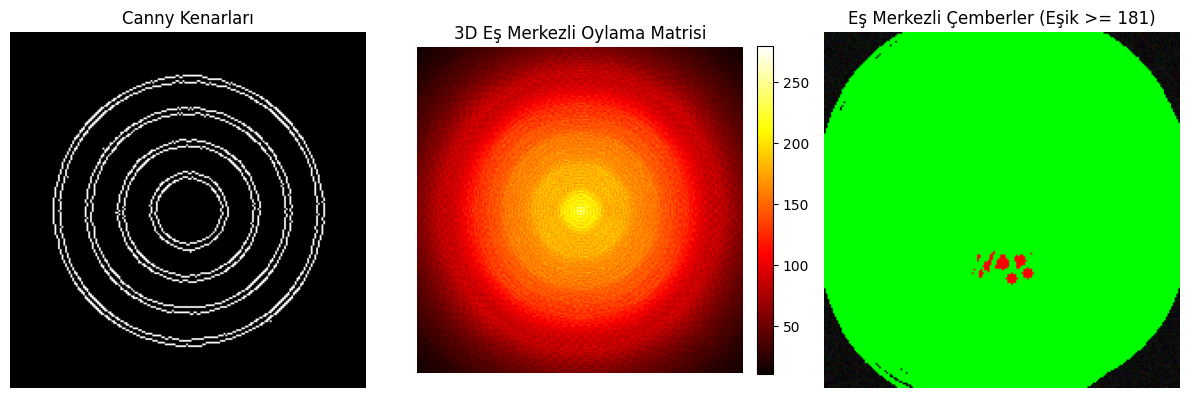

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = np.zeros((200, 200, 3), dtype=np.uint8)
center = (100, 100)  # (x, y)
for r in [20, 38, 56, 74]:
    cv2.circle(img, center, r, (255, 255, 255), 2)

noise = np.random.randint(0, 25, img.shape, dtype=np.uint8)
img = cv2.add(img, noise)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
edges = cv2.Canny(gray, 50, 150)

thetas = np.deg2rad(np.arange(0, 360, 4))
cos_vals = np.cos(thetas)
sin_vals = np.sin(thetas)

height, width = edges.shape
radii = np.arange(12, 85, 2)
num_radii = len(radii)

raw_votes_3d = np.zeros((height, width, num_radii), dtype=np.int32)
concentric_acc_3d = np.zeros((height, width, num_radii), dtype=np.int32)

edge_y, edge_x = np.nonzero(edges)

for y, x in zip(edge_y, edge_x):
    for r_idx, r in enumerate(radii):
        for c_val, s_val in zip(cos_vals, sin_vals):
            a = int(round(x - r * c_val))
            b = int(round(y - r * s_val))
            if 0 <= b < height and 0 <= a < width:
                raw_votes_3d[b, a, r_idx] += 1

for b in range(height):
    for a in range(width):
        center_profile = raw_votes_3d[b, a, :]
        if center_profile.max() > 0:
            concentric_support = np.sum(center_profile)
            for r_idx in range(num_radii):
                if center_profile[r_idx] > 0:
                    concentric_acc_3d[b, a, r_idx] = center_profile[r_idx] + int(0.5 * concentric_support)

max_val = concentric_acc_3d.max()
threshold = int(0.65 * max_val)
print(f"Maksimum eş merkezli oylama puanı: {max_val} | Eşik değer: {threshold}")

b_idxs, a_idxs, r_idxs = np.where(concentric_acc_3d >= threshold)

img_result = img.copy()
drawn_count = 0
seen = set()

for b, a, r_idx in zip(b_idxs, a_idxs, r_idxs):
    r = int(radii[r_idx])
    key = (round(a / 5), round(b / 5), r)
    if key not in seen:
        seen.add(key)
        drawn_count += 1
        cv2.circle(img_result, (a, b), r, (0, 255, 0), 2)
        cv2.circle(img_result, (a, b), 3, (0, 0, 255), -1)

print(f"Çizilen eş merkezli çember sayısı: {drawn_count}")

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(edges, cmap='gray')
plt.title('Canny Kenarları')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(concentric_acc_3d.max(axis=2), cmap='hot')
plt.title('3D Eş Merkezli Oylama Matrisi')
plt.colorbar(fraction=0.046, pad=0.04)
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(img_result, cv2.COLOR_BGR2RGB))
plt.title(f'Eş Merkezli Çemberler (Eşik >= {threshold})')
plt.axis('off')

plt.tight_layout()
plt.show()